KHÁM PHÁ DỮ LIỆU

- Đọc file

In [2]:
import pandas as pd

df = pd.read_csv(r"C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\Thanh\data\diabetes_prediction_dataset.csv")

print(df.head())
print(df.shape)

   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  
(100000, 9)


- Cấu trúc dữ liệu

In [3]:
import pandas as pd

# Nếu file dữ liệu nằm trong thư mục data cùng cấp với notebook
df = pd.read_csv("data/diabetes_prediction_dataset.csv")

# Hoặc dùng đường dẫn tuyệt đối nếu cần
# df = pd.read_csv(r"C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\Thanh\data\diabetes_prediction_dataset.csv")

print("Số dòng và số cột:", df.shape)
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("Tên thuộc tính:")
print(df.columns.tolist())

print("\n5 dòng đầu tiên:")
print(df.head())

print("\nThông tin kiểu dữ liệu từng cột:")
df.info()

Số dòng và số cột: (100000, 9)
Số dòng: 100000
Số cột: 9
Tên thuộc tính:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

5 dòng đầu tiên:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  

Thông tin kiểu dữ liệu từng cột:
<class 'pandas.DataFrame'>
RangeI

- Thống kê mô tả

In [10]:
numeric_df = df.select_dtypes(include="number")

thong_ke = numeric_df.describe().T
thong_ke["median"] = numeric_df.median()

thong_ke = thong_ke[
    ["count", "mean", "median", "std", "min", "25%", "75%", "max"]
].rename(columns={
    "count": "Số lượng",
    "mean": "Trung bình",
    "median": "Trung vị",
    "std": "Độ lệch chuẩn",
    "min": "Min",
    "25%": "Q1",
    "75%": "Q3",
    "max": "Max"
})

display(thong_ke.round(2))

,Số lượng,Trung bình,Trung vị,Độ lệch chuẩn,Min,Q1,Q3,Max
age,100000.0,41.89,43.00,22.52,0.08,24.00,60.00,80.00
hypertension,100000.0,0.07,0.00,0.26,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.04,0.00,0.19,0.00,0.00,0.00,1.00
bmi,100000.0,27.32,27.32,6.64,10.01,23.63,29.58,95.69
HbA1c_level,100000.0,5.53,5.80,1.07,3.50,4.80,6.20,9.00
blood_glucose_level,100000.0,138.06,140.00,40.71,80.00,100.00,159.00,300.00
diabetes,100000.0,0.08,0.00,0.28,0.00,0.00,0.00,1.00


- Chất lượng dữ liệu

In [11]:
import pandas as pd
import numpy as np

# Đọc dữ liệu
df = pd.read_csv("data/diabetes_prediction_dataset.csv")

# Chuyển các giá trị "No info" thành NaN
df = df.replace(["No Info", "no info", "NO INFO", "N/A", "NA", "NaN", "nan", "None", "null"], np.nan)

# Kiểm tra dữ liệu thiếu
missing = df.isna().sum().sort_values(ascending=False)

print("Số lượng dữ liệu thiếu theo từng cột:")
print(missing[missing > 0])

# Kiểm tra dữ liệu trùng lặp
dup_rows = df.duplicated().sum()
print(f"\nSố dòng trùng lặp: {dup_rows}")

# Kiểm tra ngoại lệ (Outlier)
# Dùng phương pháp IQR: [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
numeric_cols = df.select_dtypes(include=[np.number]).columns

if len(numeric_cols) > 0:
    Q1 = df[numeric_cols].quantile(0.25)
    Q3 = df[numeric_cols].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_counts = ((df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)).sum()
    outlier_counts = outlier_counts[outlier_counts > 0]

    print("\nSố lượng ngoại lệ theo cột:")
    print(outlier_counts)
    
else:
    print("\nKhông có cột số nào để kiểm tra ngoại lệ.")
missing_df = pd.DataFrame({
    "cột": missing.index,
    "số_dữ_liệu_thiếu": missing.values
})

print(missing_df)
    

Số lượng dữ liệu thiếu theo từng cột:
smoking_history    35816
dtype: int64

Số dòng trùng lặp: 3854

Số lượng ngoại lệ theo cột:
hypertension           7485
heart_disease          3942
bmi                    7086
HbA1c_level            1315
blood_glucose_level    2038
diabetes               8500
dtype: int64
                   cột  số_dữ_liệu_thiếu
0      smoking_history             35816
1               gender                 0
2                  age                 0
3         hypertension                 0
4        heart_disease                 0
5                  bmi                 0
6          HbA1c_level                 0
7  blood_glucose_level                 0
8             diabetes                 0


- Phân tích nhãn mục tiêu

,Số mẫu,Tỷ lệ (%)
Diabetes,,
0,91500,91.5
1,8500,8.5


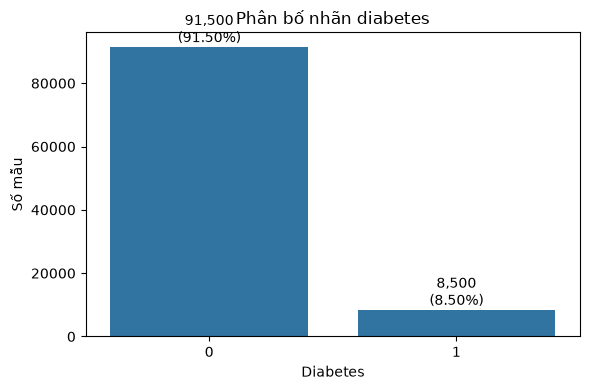

In [12]:
import seaborn as sns

import matplotlib.pyplot as plt

counts = df["diabetes"].value_counts().reindex([0, 1], fill_value=0)
percentages = counts / len(df) * 100

ket_qua = pd.DataFrame({
    "Số mẫu": counts,
    "Tỷ lệ (%)": percentages.round(2)
})
display(ket_qua.rename_axis("Diabetes"))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="diabetes", order=[0, 1])
ax.set(title="Phân bố nhãn diabetes", xlabel="Diabetes", ylabel="Số mẫu")

for bar, count, percent in zip(ax.patches, counts, percentages):
    ax.annotate(
        f"{count:,}\n({percent:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

- Phân tích từng thuộc tính

In [15]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import seaborn as sns

thu_muc_anh = Path("data/bieu_do_thuoc_tinh")
thu_muc_anh.mkdir(parents=True, exist_ok=True)

numeric_df = df.select_dtypes(include="number")

for cot in numeric_df.columns:
    du_lieu = numeric_df[cot].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(du_lieu, bins=30, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram - {cot}")
    axes[0].set_xlabel(cot)
    axes[0].set_ylabel("Tần suất")

    sns.boxplot(x=du_lieu, ax=axes[1])
    axes[1].set_title(f"Boxplot - {cot}")
    axes[1].set_xlabel(cot)

    fig.tight_layout()

    ten_file = re.sub(r'[<>:"/\\|?*]', "_", str(cot))
    fig.savefig(thu_muc_anh / f"{ten_file}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

print(f"Đã xuất {len(numeric_df.columns)} ảnh vào thư mục: {thu_muc_anh}")

Đã xuất 7 ảnh vào thư mục: data\bieu_do_thuoc_tinh


- So sánh theo nhãn

In [16]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset hiện tại dùng "diabetes"; nếu cột của bạn tên "Outcome", đổi thành "Outcome"
target_col = "diabetes"

thu_muc_anh = Path("data/bieu_do_theo_nhan")
thu_muc_anh.mkdir(parents=True, exist_ok=True)

numeric_cols = df.select_dtypes(include="number").columns.drop(
    target_col, errors="ignore"
)

for cot in numeric_cols:
    du_lieu = df[[cot, target_col]].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=du_lieu,
        x=cot,
        hue=target_col,
        bins=30,
        kde=True,
        common_norm=False,
        ax=axes[0]
    )
    axes[0].set_title(f"Histogram {cot} theo {target_col}")

    sns.boxplot(data=du_lieu, x=target_col, y=cot, ax=axes[1])
    axes[1].set_title(f"Boxplot {cot} theo {target_col}")

    fig.tight_layout()
    ten_file = re.sub(r'[<>:"/\\|?*]', "_", str(cot))
    fig.savefig(thu_muc_anh / f"{ten_file}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

print(f"Đã lưu biểu đồ vào: {thu_muc_anh}")

Đã lưu biểu đồ vào: data\bieu_do_theo_nhan


- Phân tích mối liên hệ

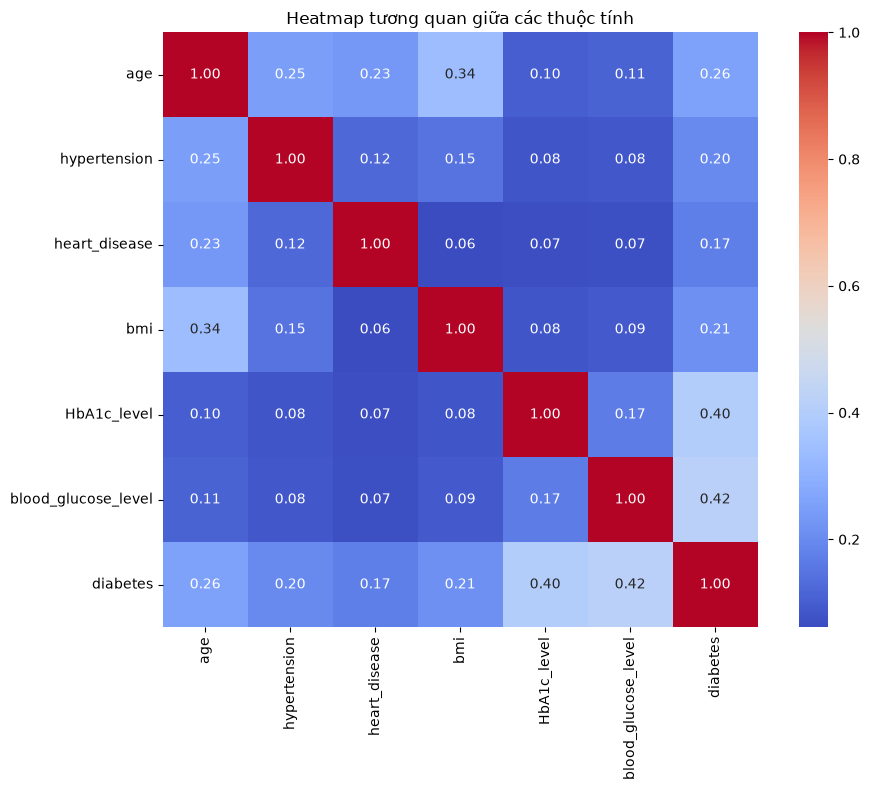

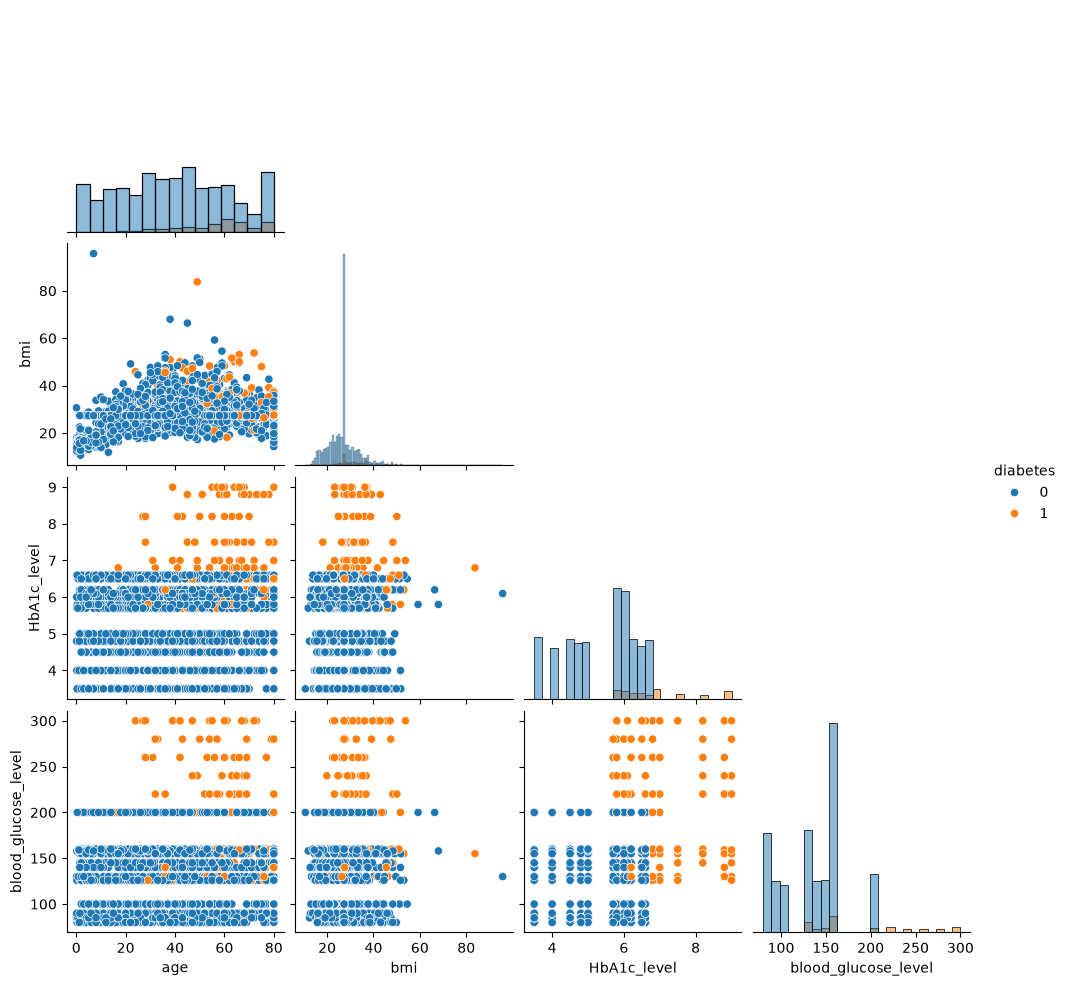

Đã lưu biểu đồ vào: data\bieu_do_moi_lien_he


In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

thu_muc_anh = Path("data/bieu_do_moi_lien_he")
thu_muc_anh.mkdir(parents=True, exist_ok=True)

# Heatmap tương quan giữa các cột số
numeric_df = df.select_dtypes(include="number")
plt.figure(figsize=(10, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True
)
plt.title("Heatmap tương quan giữa các thuộc tính")
plt.tight_layout()
plt.savefig(thu_muc_anh / "heatmap_tuong_quan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# Pairplot một số cột tiêu biểu, tô màu theo nhãn diabetes
target_col = "diabetes"
cot_chon = [
    cot for cot in ["age", "bmi", "HbA1c_level", "blood_glucose_level", target_col]
    if cot in df.columns
]

if len(cot_chon) >= 2:
    du_lieu_pairplot = df[cot_chon].dropna()

    if len(du_lieu_pairplot) > 2000:
        du_lieu_pairplot = du_lieu_pairplot.sample(
            n=2000, random_state=42
        )

    sns.pairplot(
        du_lieu_pairplot,
        hue=target_col if target_col in cot_chon else None,
        diag_kind="hist",
        corner=True
        
    )
    plt.savefig(
        thu_muc_anh / "pairplot_thuoc_tinh_tieu_bieu.png",
        dpi=150,
        bbox_inches="tight"
    )
    
    plt.show()
    plt.close()

print(f"Đã lưu biểu đồ vào: {thu_muc_anh}")